# Device Overlay Plot for One-Device Latent Heteroscedastic GP

装置ごとに保存した prediction CSV を読み込み、元素効果なしモデルの prediction interval を装置間で重ね合わせます。

この notebook では MCMC や GP fitting は実行しません。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


## 1. Settings

比較したい装置と出力先を指定します。存在しないCSVはスキップします。

In [2]:
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "2_Program":
    PROJECT_ROOT = PROJECT_ROOT.parent

OUTPUT_DIR = PROJECT_ROOT / "0_Data" / "3_Figure" / "Mineral_Mode_Relative_Error/"
FIGURE_DIR = OUTPUT_DIR 
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

OVERLAY_DEVICES = ["SR-PXRD", "LAB-PXRD", "EPMA"]
OVERLAY_DEVICES = ["EPMA", "SR-PXRD", "LAB-PXRD", ] # 


INSTRUMENT_COLORS = {
    "SR-PXRD": "#FF7F50",
    "LAB-PXRD": "#FFC107",
    "EPMA": "#9D5B8B",
}

PLOT_MEAN_ERROR = False
PLOT_PREDICTIVE_MEDIAN = True
PLOT_95_INTERVAL = True #False
PLOT_50_INTERVAL = False #True

OUTPUT_DIR, FIGURE_DIR


(PosixPath('/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error'),
 PosixPath('/Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error'))

## 2. Load Device Predictions

装置名付き prediction CSV を優先して読み込みます。古い装置名なしCSVが存在する場合は、`device` 列から装置名を読んで fallback します。

In [3]:
def safe_name(name):
    return str(name).replace("/", "-").replace(" ", "_")


def prediction_path_for_device(output_dir, device):
    return output_dir / f"one_device_latent_hgp_real_data_predictions_{safe_name(device)}.csv"


def load_device_predictions(output_dir, devices):
    predictions = {}
    missing = []

    for device in devices:
        path = prediction_path_for_device(output_dir, device)
        if not path.exists():
            missing.append((device, path))
            continue

        pred = pd.read_csv(path)
        if "device" not in pred.columns:
            pred.insert(0, "device", device)

        predictions[device] = pred

    # Fallback for older single output file. Only use it for devices not already loaded.
    fallback_path = output_dir / "one_device_latent_hgp_real_data_predictions.csv"
    if fallback_path.exists():
        fallback = pd.read_csv(fallback_path)
        if "device" in fallback.columns:
            for device, pred_i in fallback.groupby("device"):
                device = str(device)
                if device in devices and device not in predictions:
                    predictions[device] = pred_i.copy()

    print("Loaded devices:", list(predictions.keys()))
    if missing:
        print("Missing device-specific CSVs:")
        for device, path in missing:
            if device not in predictions:
                print(f"  {device}: {path}")

    if not predictions:
        raise FileNotFoundError("No prediction CSVs were found. Run the model notebook for at least one device first.")

    return predictions


predictions_by_device = load_device_predictions(OUTPUT_DIR, OVERLAY_DEVICES)

loaded_summary = []
for device, pred_i in predictions_by_device.items():
    loaded_summary.append({
        "device": device,
        "n_grid": len(pred_i),
        "x_min": pred_i["ref_wt"].min(),
        "x_max": pred_i["ref_wt"].max(),
    })

loaded_summary_df = pd.DataFrame(loaded_summary)
display(loaded_summary_df)


Loaded devices: ['EPMA', 'SR-PXRD', 'LAB-PXRD']


,device,n_grid,x_min,x_max
0,EPMA,100,0.075,72.733
1,SR-PXRD,100,0.064,75.060
2,LAB-PXRD,100,0.064,75.060


## 3. Validate Columns

重ね合わせに必要な列があるか確認します。

In [4]:
REQUIRED_COLUMNS = [
    "ref_wt",
    "pred_error_lower95",
    "pred_error_upper95",
    "pred_error_median",
    "mean_error_median",
]

for device, pred_i in predictions_by_device.items():
    missing_cols = [col for col in REQUIRED_COLUMNS if col not in pred_i.columns]
    if missing_cols:
        raise ValueError(f"{device} is missing required columns: {missing_cols}")

print("All loaded prediction tables have required columns.")


All loaded prediction tables have required columns.


## 4. Overlay Plot

装置ごとの95% prediction interval と predictive median を1枚に重ねます。

Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_prediction_interval.png
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_prediction_interval.pdf


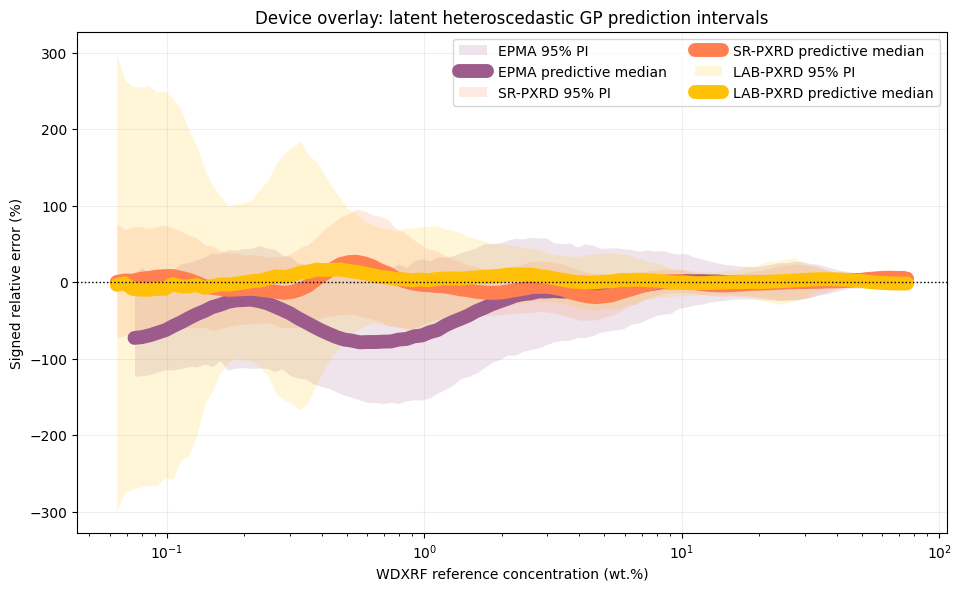

In [5]:
def plot_device_overlay_prediction(predictions_by_device, save_path_png=None, save_path_pdf=None):
    fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)

    for device in OVERLAY_DEVICES:
        if device not in predictions_by_device:
            continue

        pred_i = predictions_by_device[device].sort_values("ref_wt")
        color = INSTRUMENT_COLORS.get(device, "C0")

        if PLOT_95_INTERVAL:
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower95"],
                pred_i["pred_error_upper95"],
                color=color,
                alpha=0.16,
                linewidth=0,
                label=f"{device} 95% PI",
            )

        if PLOT_50_INTERVAL and {"pred_error_lower50", "pred_error_upper50"}.issubset(pred_i.columns):
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower50"],
                pred_i["pred_error_upper50"],
                color=color,
                alpha=0.28,
                linewidth=0,
                label=f"{device} 50% PI",
            )

        if PLOT_PREDICTIVE_MEDIAN:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["pred_error_median"],
                color=color,
                linewidth=10,
                label=f"{device} predictive median",
                solid_capstyle="round",
            )

        if PLOT_MEAN_ERROR:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["mean_error_median"],
                color=color,
                linestyle="--",
                linewidth=1.7,
                alpha=0.9,
                label=f"{device} mean error",
            )

    ax.axhline(0, color="black", linestyle=":", linewidth=1)
    ax.set_xscale("log")
    ax.set_xlabel("WDXRF reference concentration (wt.%)")
    ax.set_ylabel("Signed relative error (%)")
    ax.set_title("Device overlay: latent heteroscedastic GP prediction intervals")
    ax.grid(True, which="major", alpha=0.2)
    ax.legend(ncol=2, fontsize=10)

    if save_path_png is not None:
        save_path_png = Path(save_path_png)
        save_path_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_png, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path_png}")

    if save_path_pdf is not None:
        save_path_pdf = Path(save_path_pdf)
        save_path_pdf.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_pdf, bbox_inches="tight")
        print(f"Saved: {save_path_pdf}")

    plt.show()


plot_device_overlay_prediction(
    predictions_by_device,
    save_path_png=FIGURE_DIR / "device_overlay_prediction_interval.png",
    save_path_pdf=FIGURE_DIR / "device_overlay_prediction_interval.pdf",
)


## 5. Overlay Plot with data

保存済みの `model_data_{device}.csv` を読み込み、予測区間に観測点を重ねて表示します。存在しない装置のデータはスキップします。

Loaded model data devices: ['EPMA', 'SR-PXRD', 'LAB-PXRD']


,device,n_data,x_min,x_max,error_min,error_max
0,EPMA,80,0.075,72.733,-96.612827,43.416598
1,SR-PXRD,480,0.064,75.060,-78.614760,97.093683
2,LAB-PXRD,480,0.064,75.060,-100.000000,437.333293


Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_prediction_interval_with_data.png
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_prediction_interval_with_data.pdf


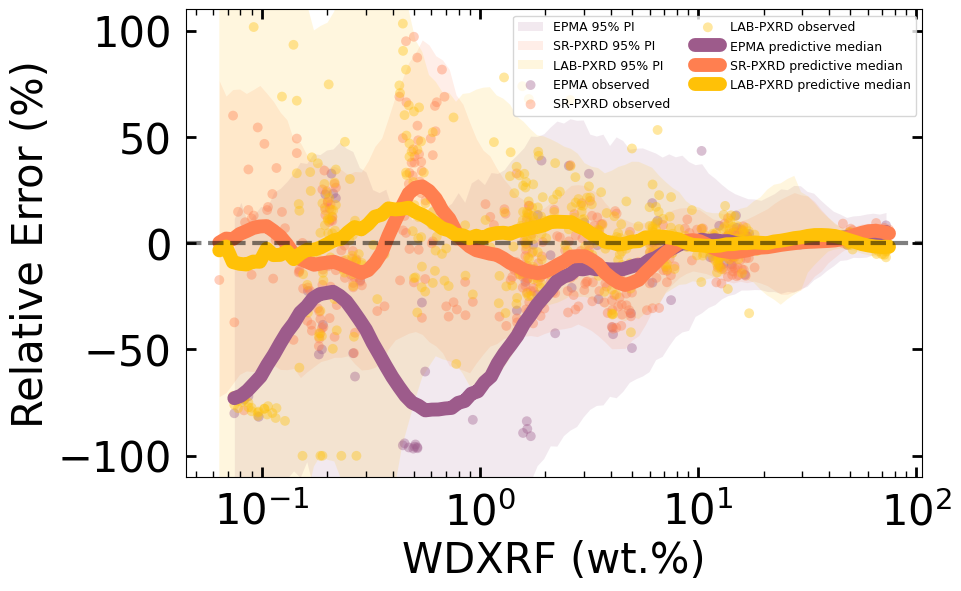

In [6]:
def model_data_path_for_device(output_dir, device):
    return output_dir / f"one_device_latent_hgp_real_data_model_data_{safe_name(device)}.csv"


def load_device_model_data(output_dir, devices):
    model_data = {}
    missing = []

    for device in devices:
        path = model_data_path_for_device(output_dir, device)
        if not path.exists():
            missing.append((device, path))
            continue

        data_i = pd.read_csv(path)
        if "device" not in data_i.columns:
            data_i.insert(0, "device", device)
        model_data[device] = data_i

    print("Loaded model data devices:", list(model_data.keys()))
    if missing:
        print("Missing model data CSVs:")
        for device, path in missing:
            if device not in model_data:
                print(f"  {device}: {path}")

    return model_data


model_data_by_device = load_device_model_data(OUTPUT_DIR, OVERLAY_DEVICES)

model_data_summary = []
for device, data_i in model_data_by_device.items():
    model_data_summary.append({
        "device": device,
        "n_data": len(data_i),
        "x_min": data_i["ref_wt"].min(),
        "x_max": data_i["ref_wt"].max(),
        "error_min": data_i["error"].min(),
        "error_max": data_i["error"].max(),
    })

model_data_summary_df = pd.DataFrame(model_data_summary)
display(model_data_summary_df)


def plot_device_overlay_prediction_with_data(
    predictions_by_device,
    model_data_by_device,
    save_path_png=None,
    save_path_pdf=None,
):
    fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)

    # Draw intervals first so observed points stay visible.
    for device in OVERLAY_DEVICES:
        if device not in predictions_by_device:
            continue

        pred_i = predictions_by_device[device].sort_values("ref_wt")
        color = INSTRUMENT_COLORS.get(device, "C0")

        if PLOT_95_INTERVAL:
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower95"],
                pred_i["pred_error_upper95"],
                color=color,
                alpha=0.13,
                linewidth=0,
                label=f"{device} 95% PI",
            )

        if PLOT_50_INTERVAL and {"pred_error_lower50", "pred_error_upper50"}.issubset(pred_i.columns):
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower50"],
                pred_i["pred_error_upper50"],
                color=color,
                alpha=0.24,
                linewidth=0,
                label=f"{device} 50% PI",
            )

    for device in OVERLAY_DEVICES:
        if device not in model_data_by_device:
            continue

        data_i = model_data_by_device[device]
        color = INSTRUMENT_COLORS.get(device, "C0")

        ax.scatter(
            data_i["ref_wt"],
            data_i["error"],
            color=color,
            s=50,
            alpha=0.38,
            edgecolor="none",
            label=f"{device} observed",
        )

    for device in OVERLAY_DEVICES:
        if device not in predictions_by_device:
            continue

        pred_i = predictions_by_device[device].sort_values("ref_wt")
        color = INSTRUMENT_COLORS.get(device, "C0")

        if PLOT_PREDICTIVE_MEDIAN:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["pred_error_median"],
                color=color,
                linewidth=10,
                label=f"{device} predictive median",
                solid_capstyle="round",
            )

        if PLOT_MEAN_ERROR:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["mean_error_median"],
                color=color,
                linestyle="--",
                linewidth=1.7,
                alpha=0.9,
                label=f"{device} mean error",
            )

    ax.axhline(0, color="black", linestyle="--", linewidth=3, alpha=0.5)
    ax.set_xscale("log")
    ax.set_xlabel("WDXRF (wt.%)", fontsize=30)
    ax.set_ylabel("Relative Error (%)", fontsize=30)
    # ax.set_title("Device overlay with observed data: latent heteroscedastic GP", pad=10)
    # ax.grid(True, which="major", alpha=0.2)
    ax.legend(ncol=2, fontsize=9)

    ax.tick_params(which='both', direction='in', bottom=True, left=True, top=True, right=True, labelsize=30, pad=10)
    ax.tick_params(which='major', length=7.5, width=2)
    ax.tick_params(which='minor', length=4, width=1)

    ax.set_ylim(-110, 110)

    if save_path_png is not None:
        save_path_png = Path(save_path_png)
        save_path_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_png, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path_png}")

    if save_path_pdf is not None:
        save_path_pdf = Path(save_path_pdf)
        save_path_pdf.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_pdf, bbox_inches="tight")
        print(f"Saved: {save_path_pdf}")

    plt.show()


plot_device_overlay_prediction_with_data(
    predictions_by_device,
    model_data_by_device,
    save_path_png=FIGURE_DIR / "device_overlay_prediction_interval_with_data.png",
    save_path_pdf=FIGURE_DIR / "device_overlay_prediction_interval_with_data.pdf",
)


Loaded model data devices: ['EPMA', 'SR-PXRD', 'LAB-PXRD']


,device,n_data,x_min,x_max,error_min,error_max
0,EPMA,80,0.075,72.733,-96.612827,43.416598
1,SR-PXRD,480,0.064,75.060,-78.614760,97.093683
2,LAB-PXRD,480,0.064,75.060,-100.000000,437.333293


Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_prediction_interval_with_data.png
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_prediction_interval_with_data.pdf


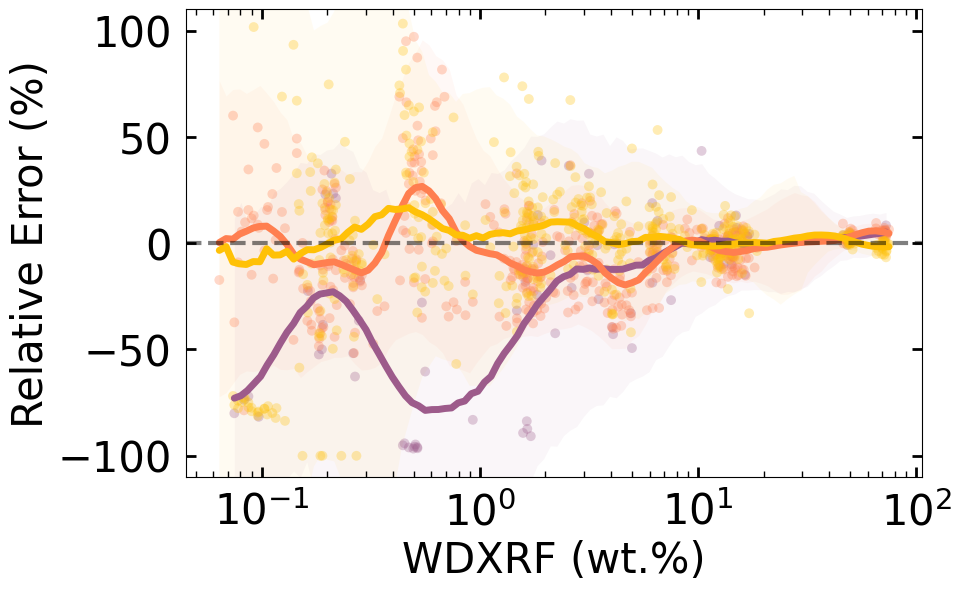

In [22]:
def model_data_path_for_device(output_dir, device):
    return output_dir / f"one_device_latent_hgp_real_data_model_data_{safe_name(device)}.csv"


def load_device_model_data(output_dir, devices):
    model_data = {}
    missing = []

    for device in devices:
        path = model_data_path_for_device(output_dir, device)
        if not path.exists():
            missing.append((device, path))
            continue

        data_i = pd.read_csv(path)
        if "device" not in data_i.columns:
            data_i.insert(0, "device", device)
        model_data[device] = data_i

    print("Loaded model data devices:", list(model_data.keys()))
    if missing:
        print("Missing model data CSVs:")
        for device, path in missing:
            if device not in model_data:
                print(f"  {device}: {path}")

    return model_data


model_data_by_device = load_device_model_data(OUTPUT_DIR, OVERLAY_DEVICES)

model_data_summary = []
for device, data_i in model_data_by_device.items():
    model_data_summary.append({
        "device": device,
        "n_data": len(data_i),
        "x_min": data_i["ref_wt"].min(),
        "x_max": data_i["ref_wt"].max(),
        "error_min": data_i["error"].min(),
        "error_max": data_i["error"].max(),
    })

model_data_summary_df = pd.DataFrame(model_data_summary)
display(model_data_summary_df)


def plot_device_overlay_prediction_with_data(
    predictions_by_device,
    model_data_by_device,
    save_path_png=None,
    save_path_pdf=None,
):
    fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)

    # Draw intervals first so observed points stay visible.
    for device in OVERLAY_DEVICES:
        if device not in predictions_by_device:
            continue

        pred_i = predictions_by_device[device].sort_values("ref_wt")
        color = INSTRUMENT_COLORS.get(device, "C0")

        if PLOT_95_INTERVAL:
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower95"],
                pred_i["pred_error_upper95"],
                color=color,
                alpha=0.05,
                linewidth=0,
                label=f"{device} 95% PI",
            )
            # ax.plot(
            #     pred_i["ref_wt"],
            #     pred_i["pred_error_lower95"],
            #     color=color,
            #     linewidth=10,
            #     alpha=0.3,
            #     linestyle="-",
            #     label="_nolegend_",
            # )

            # ax.plot(
            #     pred_i["ref_wt"],
            #     pred_i["pred_error_upper95"],
            #     color=color,
            #     linewidth=10,
            #     alpha=0.3,
            #     linestyle="-",
            #     label="_nolegend_",
            # )            

        if PLOT_50_INTERVAL and {"pred_error_lower50", "pred_error_upper50"}.issubset(pred_i.columns):
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower50"],
                pred_i["pred_error_upper50"],
                color=color,
                alpha=0.24,
                linewidth=0,
                label=f"{device} 50% PI",
            )

    for device in OVERLAY_DEVICES:
        if device not in model_data_by_device:
            continue

        data_i = model_data_by_device[device]
        color = INSTRUMENT_COLORS.get(device, "C0")

        ax.scatter(
            data_i["ref_wt"],
            data_i["error"],
            color=color,
            s=50,
            alpha=0.3,
            edgecolor="none",
            label=f"{device} observed",
        )

    for device in OVERLAY_DEVICES:
        if device not in predictions_by_device:
            continue

        pred_i = predictions_by_device[device].sort_values("ref_wt")
        color = INSTRUMENT_COLORS.get(device, "C0")

        if PLOT_PREDICTIVE_MEDIAN:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["pred_error_median"],
                color=color,
                linewidth=5,
                label=f"{device} predictive median",
                solid_capstyle="round",
            )

        if PLOT_MEAN_ERROR:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["mean_error_median"],
                color=color,
                linestyle="--",
                linewidth=1.7,
                alpha=0.9,
                label=f"{device} mean error",
            )

    ax.axhline(0, color="black", linestyle="--", linewidth=3, alpha=0.5)
    ax.set_xscale("log")
    ax.set_xlabel("WDXRF (wt.%)", fontsize=30)
    ax.set_ylabel("Relative Error (%)", fontsize=30)
    # ax.set_title("Device overlay with observed data: latent heteroscedastic GP", pad=10)
    # ax.grid(True, which="major", alpha=0.2)
    # ax.legend(ncol=2, fontsize=9)

    ax.tick_params(which='both', direction='in', bottom=True, left=True, top=True, right=True, labelsize=30, pad=10)
    ax.tick_params(which='major', length=7.5, width=2)
    ax.tick_params(which='minor', length=4, width=1)

    ax.set_ylim(-110, 110)

    if save_path_png is not None:
        save_path_png = Path(save_path_png)
        save_path_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_png, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path_png}")

    if save_path_pdf is not None:
        save_path_pdf = Path(save_path_pdf)
        save_path_pdf.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_pdf, bbox_inches="tight")
        print(f"Saved: {save_path_pdf}")

    plt.show()


plot_device_overlay_prediction_with_data(
    predictions_by_device,
    model_data_by_device,
    save_path_png=FIGURE_DIR / "device_overlay_prediction_interval_with_data.png",
    save_path_pdf=FIGURE_DIR / "device_overlay_prediction_interval_with_data.pdf",
)


Loaded model data devices: ['EPMA', 'SR-PXRD', 'LAB-PXRD']


,device,n_data,x_min,x_max,error_min,error_max
0,EPMA,80,0.075,72.733,-96.612827,43.416598
1,SR-PXRD,480,0.064,75.060,-78.614760,97.093683
2,LAB-PXRD,480,0.064,75.060,-100.000000,437.333293


Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_prediction_interval_with_data_wide.png
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_prediction_interval_with_data_wide.pdf


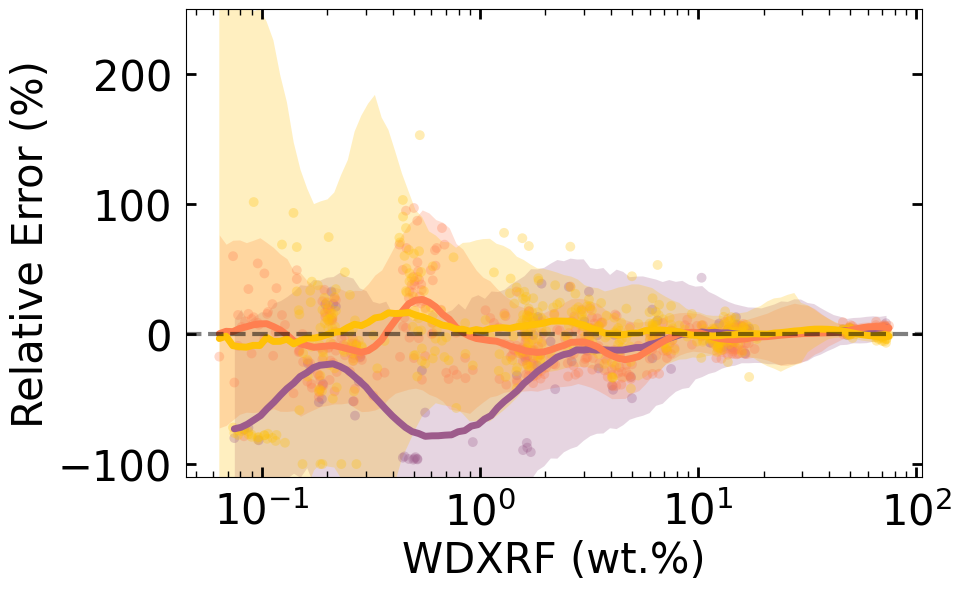

In [25]:
def model_data_path_for_device(output_dir, device):
    return output_dir / f"one_device_latent_hgp_real_data_model_data_{safe_name(device)}.csv"


def load_device_model_data(output_dir, devices):
    model_data = {}
    missing = []

    for device in devices:
        path = model_data_path_for_device(output_dir, device)
        if not path.exists():
            missing.append((device, path))
            continue

        data_i = pd.read_csv(path)
        if "device" not in data_i.columns:
            data_i.insert(0, "device", device)
        model_data[device] = data_i

    print("Loaded model data devices:", list(model_data.keys()))
    if missing:
        print("Missing model data CSVs:")
        for device, path in missing:
            if device not in model_data:
                print(f"  {device}: {path}")

    return model_data


model_data_by_device = load_device_model_data(OUTPUT_DIR, OVERLAY_DEVICES)

model_data_summary = []
for device, data_i in model_data_by_device.items():
    model_data_summary.append({
        "device": device,
        "n_data": len(data_i),
        "x_min": data_i["ref_wt"].min(),
        "x_max": data_i["ref_wt"].max(),
        "error_min": data_i["error"].min(),
        "error_max": data_i["error"].max(),
    })

model_data_summary_df = pd.DataFrame(model_data_summary)
display(model_data_summary_df)


def plot_device_overlay_prediction_with_data(
    predictions_by_device,
    model_data_by_device,
    save_path_png=None,
    save_path_pdf=None,
):
    fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)

    # Draw intervals first so observed points stay visible.
    for device in OVERLAY_DEVICES:
        if device not in predictions_by_device:
            continue

        pred_i = predictions_by_device[device].sort_values("ref_wt")
        color = INSTRUMENT_COLORS.get(device, "C0")

        if PLOT_95_INTERVAL:
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower95"],
                pred_i["pred_error_upper95"],
                color=color,
                alpha=0.25,
                linewidth=0,
                label=f"{device} 95% PI",
            )
            # ax.plot(
            #     pred_i["ref_wt"],
            #     pred_i["pred_error_lower95"],
            #     color=color,
            #     linewidth=10,
            #     alpha=0.3,
            #     linestyle="-",
            #     label="_nolegend_",
            # )

            # ax.plot(
            #     pred_i["ref_wt"],
            #     pred_i["pred_error_upper95"],
            #     color=color,
            #     linewidth=10,
            #     alpha=0.3,
            #     linestyle="-",
            #     label="_nolegend_",
            # )            

        if PLOT_50_INTERVAL and {"pred_error_lower50", "pred_error_upper50"}.issubset(pred_i.columns):
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower50"],
                pred_i["pred_error_upper50"],
                color=color,
                alpha=0.24,
                linewidth=0,
                label=f"{device} 50% PI",
            )

    for device in OVERLAY_DEVICES:
        if device not in model_data_by_device:
            continue

        data_i = model_data_by_device[device]
        color = INSTRUMENT_COLORS.get(device, "C0")

        ax.scatter(
            data_i["ref_wt"],
            data_i["error"],
            color=color,
            s=50,
            alpha=0.3,
            edgecolor="none",
            label=f"{device} observed",
        )

    for device in OVERLAY_DEVICES:
        if device not in predictions_by_device:
            continue

        pred_i = predictions_by_device[device].sort_values("ref_wt")
        color = INSTRUMENT_COLORS.get(device, "C0")

        if PLOT_PREDICTIVE_MEDIAN:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["pred_error_median"],
                color=color,
                linewidth=5,
                label=f"{device} predictive median",
                solid_capstyle="round",
            )

        if PLOT_MEAN_ERROR:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["mean_error_median"],
                color=color,
                linestyle="--",
                linewidth=1.7,
                alpha=0.9,
                label=f"{device} mean error",
            )

    ax.axhline(0, color="black", linestyle="--", linewidth=3, alpha=0.5)
    ax.set_xscale("log")
    ax.set_xlabel("WDXRF (wt.%)", fontsize=30)
    ax.set_ylabel("Relative Error (%)", fontsize=30)
    # ax.set_title("Device overlay with observed data: latent heteroscedastic GP", pad=10)
    # ax.grid(True, which="major", alpha=0.2)
    # ax.legend(ncol=2, fontsize=9)

    ax.tick_params(which='both', direction='in', bottom=True, left=True, top=True, right=True, labelsize=30, pad=10)
    ax.tick_params(which='major', length=7.5, width=2)
    ax.tick_params(which='minor', length=4, width=1)

    ax.set_ylim(-110, 250)

    if save_path_png is not None:
        save_path_png = Path(save_path_png)
        save_path_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_png, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path_png}")

    if save_path_pdf is not None:
        save_path_pdf = Path(save_path_pdf)
        save_path_pdf.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_pdf, bbox_inches="tight")
        print(f"Saved: {save_path_pdf}")

    plt.show()


plot_device_overlay_prediction_with_data(
    predictions_by_device,
    model_data_by_device,
    save_path_png=FIGURE_DIR / "device_overlay_prediction_interval_with_data_wide.png",
    save_path_pdf=FIGURE_DIR / "device_overlay_prediction_interval_with_data_wide.pdf",
)


Loaded model data devices: ['EPMA', 'SR-PXRD', 'LAB-PXRD']


,device,n_data,x_min,x_max,error_min,error_max
0,EPMA,80,0.075,72.733,-96.612827,43.416598
1,SR-PXRD,480,0.064,75.060,-78.614760,97.093683
2,LAB-PXRD,480,0.064,75.060,-100.000000,437.333293


Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_prediction_interval_with_data_.png
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_prediction_interval_with_data_.pdf


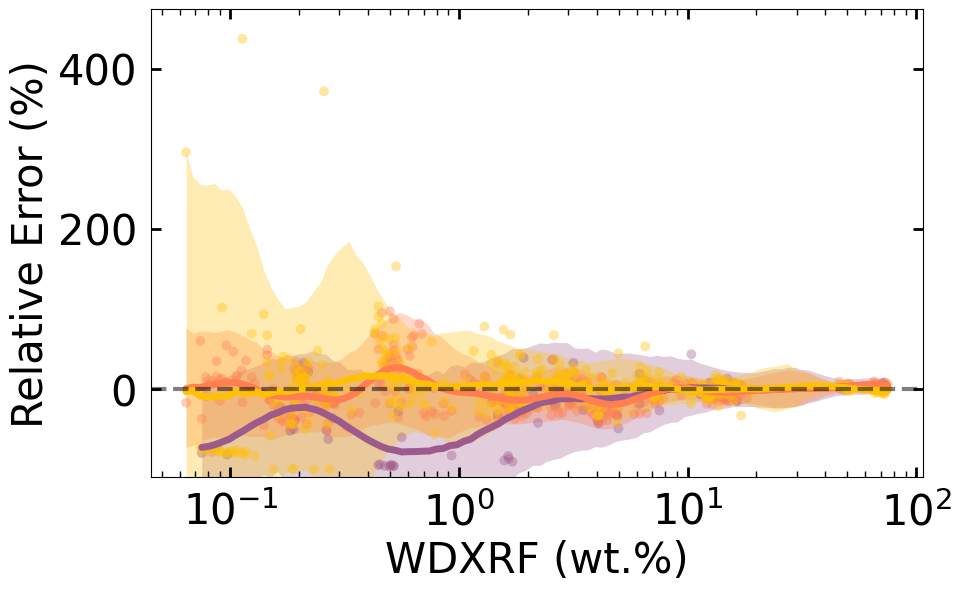

In [26]:
def model_data_path_for_device(output_dir, device):
    return output_dir / f"one_device_latent_hgp_real_data_model_data_{safe_name(device)}.csv"


def load_device_model_data(output_dir, devices):
    model_data = {}
    missing = []

    for device in devices:
        path = model_data_path_for_device(output_dir, device)
        if not path.exists():
            missing.append((device, path))
            continue

        data_i = pd.read_csv(path)
        if "device" not in data_i.columns:
            data_i.insert(0, "device", device)
        model_data[device] = data_i

    print("Loaded model data devices:", list(model_data.keys()))
    if missing:
        print("Missing model data CSVs:")
        for device, path in missing:
            if device not in model_data:
                print(f"  {device}: {path}")

    return model_data


model_data_by_device = load_device_model_data(OUTPUT_DIR, OVERLAY_DEVICES)

model_data_summary = []
for device, data_i in model_data_by_device.items():
    model_data_summary.append({
        "device": device,
        "n_data": len(data_i),
        "x_min": data_i["ref_wt"].min(),
        "x_max": data_i["ref_wt"].max(),
        "error_min": data_i["error"].min(),
        "error_max": data_i["error"].max(),
    })

model_data_summary_df = pd.DataFrame(model_data_summary)
display(model_data_summary_df)


def plot_device_overlay_prediction_with_data(
    predictions_by_device,
    model_data_by_device,
    save_path_png=None,
    save_path_pdf=None,
):
    fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)

    # Draw intervals first so observed points stay visible.
    for device in OVERLAY_DEVICES:
        if device not in predictions_by_device:
            continue

        pred_i = predictions_by_device[device].sort_values("ref_wt")
        color = INSTRUMENT_COLORS.get(device, "C0")

        if PLOT_95_INTERVAL:
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower95"],
                pred_i["pred_error_upper95"],
                color=color,
                alpha=0.3,
                linewidth=0,
                label=f"{device} 95% PI",
            )

        if PLOT_50_INTERVAL and {"pred_error_lower50", "pred_error_upper50"}.issubset(pred_i.columns):
            ax.fill_between(
                pred_i["ref_wt"],
                pred_i["pred_error_lower50"],
                pred_i["pred_error_upper50"],
                color=color,
                alpha=0.24,
                linewidth=0,
                label=f"{device} 50% PI",
            )

    for device in OVERLAY_DEVICES:
        if device not in model_data_by_device:
            continue

        data_i = model_data_by_device[device]
        color = INSTRUMENT_COLORS.get(device, "C0")

        ax.scatter(
            data_i["ref_wt"],
            data_i["error"],
            color=color,
            s=50,
            alpha=0.38,
            edgecolor="none",
            label=f"{device} observed",
        )

    for device in OVERLAY_DEVICES:
        if device not in predictions_by_device:
            continue

        pred_i = predictions_by_device[device].sort_values("ref_wt")
        color = INSTRUMENT_COLORS.get(device, "C0")

        if PLOT_PREDICTIVE_MEDIAN:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["pred_error_median"],
                color=color,
                linewidth=5,
                label=f"{device} predictive median",
                solid_capstyle="round",
            )

        if PLOT_MEAN_ERROR:
            ax.plot(
                pred_i["ref_wt"],
                pred_i["mean_error_median"],
                color=color,
                linestyle="--",
                linewidth=1.7,
                alpha=0.9,
                label=f"{device} mean error",
            )

    ax.axhline(0, color="black", linestyle="--", linewidth=3, alpha=0.5)
    ax.set_xscale("log")
    ax.set_xlabel("WDXRF (wt.%)", fontsize=30)
    ax.set_ylabel("Relative Error (%)", fontsize=30)
    # ax.set_title("Device overlay with observed data: latent heteroscedastic GP", pad=10)
    # ax.grid(True, which="major", alpha=0.2)
    # ax.legend(ncol=2, fontsize=9)

    ax.tick_params(which='both', direction='in', bottom=True, left=True, top=True, right=True, labelsize=30, pad=10)
    ax.tick_params(which='major', length=7.5, width=2)
    ax.tick_params(which='minor', length=4, width=1)

    ax.set_ylim(-110, None)

    if save_path_png is not None:
        save_path_png = Path(save_path_png)
        save_path_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_png, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path_png}")

    if save_path_pdf is not None:
        save_path_pdf = Path(save_path_pdf)
        save_path_pdf.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_pdf, bbox_inches="tight")
        print(f"Saved: {save_path_pdf}")

    plt.show()


plot_device_overlay_prediction_with_data(
    predictions_by_device,
    model_data_by_device,
    save_path_png=FIGURE_DIR / "device_overlay_prediction_interval_with_data_.png",
    save_path_pdf=FIGURE_DIR / "device_overlay_prediction_interval_with_data_.pdf",
)


## 6. Overlay Estimated Heteroscedasticity

装置ごとの estimated heteroscedasticity を重ねて比較します。

ここでは、各装置の prediction CSV に保存されている `sigma_median`, `sigma_lower95`, `sigma_upper95` を使います。`sigma(x)` は signed relative error の推定標準偏差であり、濃度ごとの誤差幅を表します。


All loaded prediction tables have required sigma columns.
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_estimated_heteroscedasticity.png
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_estimated_heteroscedasticity.pdf


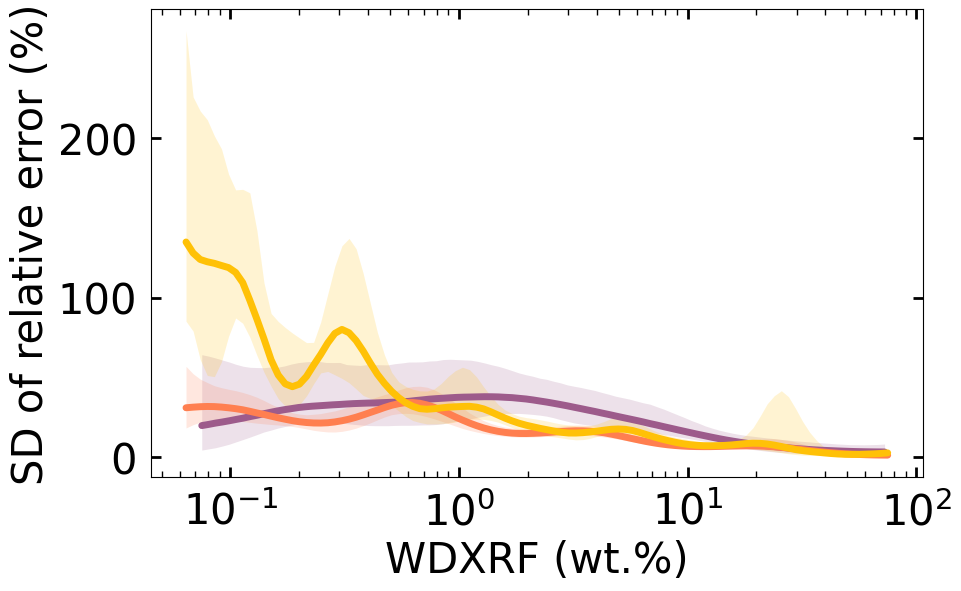

In [27]:
SIGMA_REQUIRED_COLUMNS = [
    "ref_wt",
    "sigma_median",
    "sigma_lower95",
    "sigma_upper95",
]

for device, pred_i in predictions_by_device.items():
    missing_cols = [col for col in SIGMA_REQUIRED_COLUMNS if col not in pred_i.columns]
    if missing_cols:
        raise ValueError(f"{device} is missing required sigma columns: {missing_cols}")

print("All loaded prediction tables have required sigma columns.")


def plot_device_overlay_sigma(
    predictions_by_device,
    save_path_png=None,
    save_path_pdf=None,
):
    fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)

    for device in OVERLAY_DEVICES:
        if device not in predictions_by_device:
            continue

        pred_i = predictions_by_device[device].sort_values("ref_wt")
        color = INSTRUMENT_COLORS.get(device, "C0")

        ax.fill_between(
            pred_i["ref_wt"],
            pred_i["sigma_lower95"],
            pred_i["sigma_upper95"],
            color=color,
            alpha=0.18,
            linewidth=0,
            label=f"{device} sigma 95% CI",
        )

        ax.plot(
            pred_i["ref_wt"],
            pred_i["sigma_median"],
            color=color,
            linewidth=5,
            label=f"{device} sigma median",
            solid_capstyle="round",
        )

    ax.set_xscale("log")
    ax.set_xlabel("WDXRF (wt.%)", fontsize=30)
    ax.set_ylabel("SD of relative error (%)", fontsize=30)
    # ax.set_title("Device overlay: estimated heteroscedasticity", pad=10)
    # ax.grid(True, which="major", alpha=0.2)
    # ax.legend(ncol=2, fontsize=9)

    ax.tick_params(which="both", direction="in", bottom=True, left=True, top=True, right=True, labelsize=30, pad=10)
    ax.tick_params(which="major", length=7.5, width=2)
    ax.tick_params(which="minor", length=4, width=1)

    if save_path_png is not None:
        save_path_png = Path(save_path_png)
        save_path_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_png, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path_png}")

    if save_path_pdf is not None:
        save_path_pdf = Path(save_path_pdf)
        save_path_pdf.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_pdf, bbox_inches="tight")
        print(f"Saved: {save_path_pdf}")

    plt.show()


plot_device_overlay_sigma(
    predictions_by_device,
    save_path_png=FIGURE_DIR / "device_overlay_estimated_heteroscedasticity.png",
    save_path_pdf=FIGURE_DIR / "device_overlay_estimated_heteroscedasticity.pdf",
)


Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_estimated_heteroscedasticity_with_observed_error.png
Saved: /Volumes/SSD-PHPU3A/研究/0_DATA/6_EPMA_XRD検証/0_Data/3_Figure/Mineral_Mode_Relative_Error/device_overlay_estimated_heteroscedasticity_with_observed_error.pdf


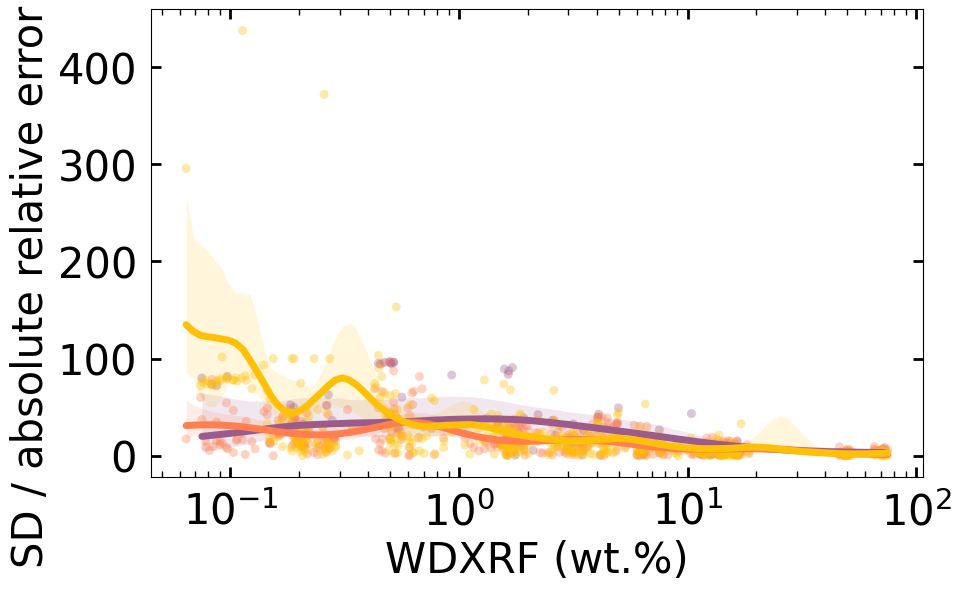

In [28]:
def plot_device_overlay_sigma_with_observed_error(
    predictions_by_device,
    model_data_by_device,
    save_path_png=None,
    save_path_pdf=None,
):
    fig, ax = plt.subplots(figsize=(9.5, 5.8), constrained_layout=True)

    for device in OVERLAY_DEVICES:
        if device not in predictions_by_device:
            continue

        pred_i = predictions_by_device[device].sort_values("ref_wt")
        color = INSTRUMENT_COLORS.get(device, "C0")

        ax.fill_between(
            pred_i["ref_wt"],
            pred_i["sigma_lower95"],
            pred_i["sigma_upper95"],
            color=color,
            alpha=0.14,
            linewidth=0,
            label=f"{device} sigma 95% CI",
        )

    for device in OVERLAY_DEVICES:
        if device not in model_data_by_device:
            continue

        data_i = model_data_by_device[device]
        color = INSTRUMENT_COLORS.get(device, "C0")

        ax.scatter(
            data_i["ref_wt"],
            data_i["error"].abs(),
            color=color,
            s=42,
            alpha=0.34,
            edgecolor="none",
            label=f"{device} observed |error|",
        )

    for device in OVERLAY_DEVICES:
        if device not in predictions_by_device:
            continue

        pred_i = predictions_by_device[device].sort_values("ref_wt")
        color = INSTRUMENT_COLORS.get(device, "C0")

        ax.plot(
            pred_i["ref_wt"],
            pred_i["sigma_median"],
            color=color,
            linewidth=5,
            label=f"{device} sigma median",
            solid_capstyle="round",
        )

    ax.set_xscale("log")
    ax.set_xlabel("WDXRF (wt.%)", fontsize=30)
    ax.set_ylabel("SD / absolute relative error (%)", fontsize=30)
    # ax.set_title("Device overlay: estimated heteroscedasticity with observed error", pad=10)
    # ax.grid(True, which="major", alpha=0.2)
    # ax.legend(ncol=2, fontsize=9)

    ax.tick_params(which="both", direction="in", bottom=True, left=True, top=True, right=True, labelsize=30, pad=10)
    ax.tick_params(which="major", length=7.5, width=2)
    ax.tick_params(which="minor", length=4, width=1)

    if save_path_png is not None:
        save_path_png = Path(save_path_png)
        save_path_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_png, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path_png}")

    if save_path_pdf is not None:
        save_path_pdf = Path(save_path_pdf)
        save_path_pdf.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path_pdf, bbox_inches="tight")
        print(f"Saved: {save_path_pdf}")

    plt.show()


plot_device_overlay_sigma_with_observed_error(
    predictions_by_device,
    model_data_by_device,
    save_path_png=FIGURE_DIR / "device_overlay_estimated_heteroscedasticity_with_observed_error.png",
    save_path_pdf=FIGURE_DIR / "device_overlay_estimated_heteroscedasticity_with_observed_error.pdf",
)
